# Homework 3

## Task 1: Connect the Model to Real Data

**Dataset:** We are using the publicly available Hugging Face dataset `karan-0123/air-quality`.

**Data Table:** The data includes a timestamp (`datetime`), model inputs (wind speed `wind`, relative humidity `rh`), and a measured output (outdoor `pm25`).


In [1]:
def preprocess_data(df, time_col='datetime'):
    # Drop rows with any missing values
    df_clean = df.dropna()

    # Drop duplicates based on the time column, keeping the first occurrence
    df_clean = df_clean.drop_duplicates(subset=[time_col], keep='first')
    
    # Index reset for continuity after dropping rows
    return df_clean.reset_index(drop=True)

Initial dataset shape: (87672, 11)
Dataset shape after preprocessing: (87672, 11)


,datetime,wind,rh,pm25
0,2015-01-01 00:00:00,0.1,42.058440,150.849670
1,2015-01-01 01:00:00,0.1,37.960572,132.370120
2,2015-01-01 02:00:00,0.1,37.412200,157.994518
3,2015-01-01 03:00:00,0.1,17.713272,173.358215
4,2015-01-01 04:00:00,0.1,39.903303,201.753827


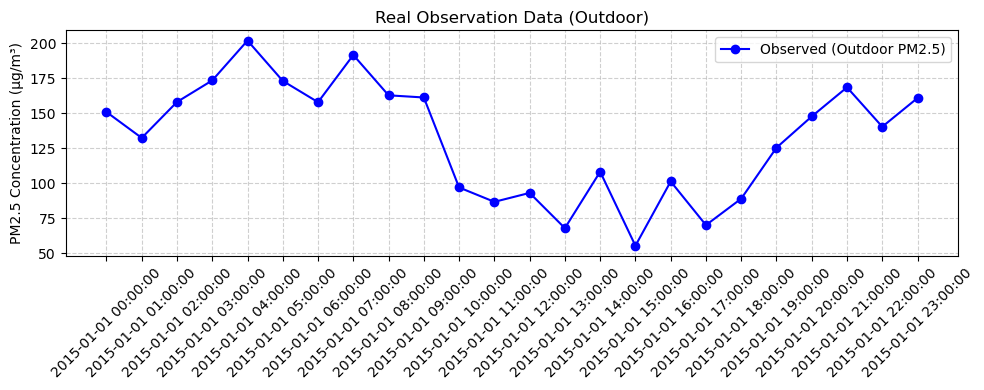

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Load a sample of the historical dataset
df = pd.read_csv('hf://datasets/karan-0123/air-quality/air_quality.csv')
print(f"Initial dataset shape: {df.shape}")

#Preprocess the data to remove missing values and duplicates
df = preprocess_data(df)
print(f"Dataset shape after preprocessing: {df.shape}")

df_day = df[:24].copy() # Using 24 hours of data

# Display a small data table
display(df_day[['datetime', 'wind', 'rh', 'pm25']].head())

# Plot the observed output over time
plt.figure(figsize=(10, 4))
plt.plot(df_day['datetime'], df_day['pm25'], label='Observed (Outdoor PM2.5)', color='blue', marker='o')
plt.xticks(rotation=45)
plt.ylabel('PM2.5 Concentration (µg/m³)')
plt.title('Real Observation Data (Outdoor)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## Task 2: Compare Simulation and Observation

We use our existing model (Mass Balance Equation) to generate simulated indoor outputs for the same 24-hour period covered by the outdoor observational dataset.

**Discussion:**
- **Similarities/Differences:** The simulated indoor PM2.5 values are significantly smoother and react with a delay compared to the outdoor measurements.
- **Explanation:** This difference is expected because the simulation accounts for the building's infiltration rate (dependent on wind speed) and deposition rate (dependent on humidity). Furthermore, we are plotting simulated *indoor* air quality against measured *outdoor* air quality. Full alignment would require indoor sensor data.

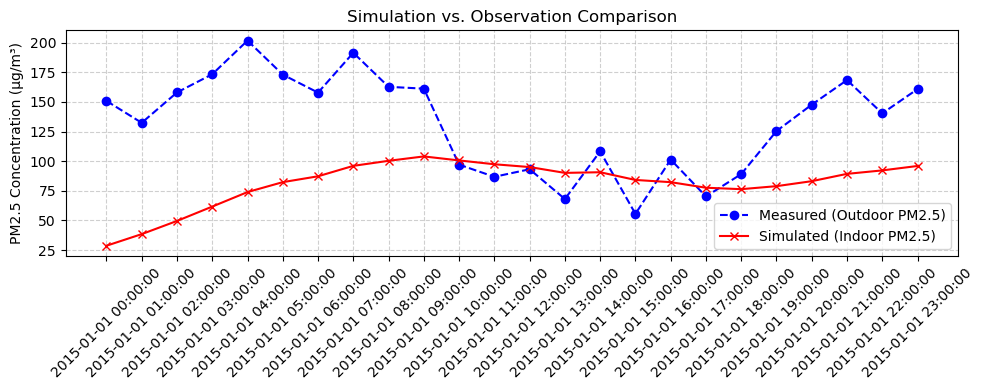

In [3]:
# Existing advanced simulation logic
def simulate_advanced_indoor_aq(data, k_base=0.1, c_w=0.05, c_h=0.001, alpha_source=0.0, beta_purifier=0.0):
    delta_t = 1
    PM_in_initial = 15.0
    PM_in_list = [PM_in_initial]
    
    for i in range(len(data)):
        PM_in_prev = PM_in_list[-1]
        PM_out = data['pm25'].iloc[i]
        v = data['wind'].iloc[i]
        h = data['rh'].iloc[i]
        
        # Dynamic parameters
        k_v = k_base + c_w * v
        gamma_h = c_h * h
        
        # Calculate change
        change = delta_t * (k_v * (PM_out - PM_in_prev) - gamma_h * PM_in_prev + alpha_source - beta_purifier)
        PM_in_new = max(0, PM_in_prev + change)
        PM_in_list.append(PM_in_new)
        
    return PM_in_list[1:]

# Run simulation
simulated_pm25 = simulate_advanced_indoor_aq(df_day)

# Plotting the comparison
plt.figure(figsize=(10, 4))
plt.plot(df_day['datetime'], df_day['pm25'], label='Measured (Outdoor PM2.5)', linestyle='--', color='blue', marker='o')
plt.plot(df_day['datetime'], simulated_pm25, label='Simulated (Indoor PM2.5)', color='red', marker='x')
plt.xticks(rotation=45)
plt.ylabel('PM2.5 Concentration (µg/m³)')
plt.title('Simulation vs. Observation Comparison')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## Task 3: Design the Digital Twin Architecture

**Architecture Flow:**
1. **Physical System:** The building and its surrounding environment.
2. **Observations:** Outdoor Weather API (PM2.5, Wind, Humidity) & Indoor PM2.5 Sensor.
3. **Data Processing:** Handling missing values, duplicate timestamps, and data formatting.
4. **Simulation Model:** Extended Mass Balance Equation updating the state.
5. **Model Outputs:** Corrected and predicted Indoor Air Quality (PM2.5).

**Proposed Synchronization:**
When a new real observation is received from the physical indoor sensor, the internal state variable `$PM_{in}(t-1)$` in the simulation will be updated (overwritten) with this ground-truth value. This eliminates accumulating errors (drift) before the next time step is calculated.

```mermaid
flowchart LR
    A["<b>1. Physical System</b><br/>Building & Outdoor Env"] --> B["<b>2. Historical Observations</b><br/>HF Dataset: PM2.5, Wind, RH"]
    B --> C["<b>3. Data Processing</b><br/>Drop NaNs & Duplicates,<br/>Format 24h Window"]
    C --> D["<b>4. Simulation Model</b><br/>Extended Mass Balance Eq.<br/>k(v), γ(h), Source, Purifier"]
    D --> E["<b>5. Model Outputs</b><br/>Predicted Indoor PM2.5<br/>& What-If Scenarios"]
    
    S["<b>Real-Time Indoor Sensor</b><br/>Ground-Truth PM_in"] -. "Synchronization<br/>(Overwrite PM_in(t-1))" .-> D
    A -.-> S
```

## Task 4: Prepare for Week 4

**1. Which measured variable will you use to synchronize your Digital Twin?**

We will use the **indoor PM2.5 concentration** ($PM_{in}$) to synchronize the core state of the Digital Twin. The outdoor PM2.5 ($PM_{out}$) and weather parameters will be continuously updated as boundary conditions/inputs.

**2. How frequently can the model be updated?**

The model will be updated **hourly**. This matches both the frequency of the Hugging Face dataset (which provides hourly meteorological and air quality data) and the defined time step of our simulation ($\Delta t = 1$).

**3. How will you predict the next time step after synchronization?**

After synchronizing the state variable $PM_{in}(t-1)$ with the actual sensor measurement, we will plug this true value into the **Mass Balance Equation**. Using the newly received outdoor inputs (wind, humidity, outdoor PM2.5), the model will calculate the expected change over the next hour and output the predicted $PM_{in}(t)$ for the next time step.

# Potentially Useful API'S

1. **OpenWeatherMap API**: Provides real-time weather data including wind speed and humidity.
2. https://openair.foundation/projects/indoor-aq-map

### Architecture Components:

1. **Physical System:** 
   The indoor building environment (including internal pollution sources like cooking and sinks like air purifiers) and its surrounding outdoor meteorological environment.
2. **Historical Observations (& Real-Time Inputs):** 
   * *Historical Data (Current):* Publicly available hourly dataset (`karan-0123/air-quality` from Hugging Face) containing `datetime`, outdoor `pm25`, wind speed (`wind`), and relative humidity (`rh`).
   * *Real-Time Observations (Synchronization):* Outdoor Weather API (OpenWeatherMap) for boundary conditions and a physical Indoor PM2.5 Sensor (OpenAir) for ground-truth state updates.
3. **Data Processing (`preprocess_data`):** 
   Automated data cleaning pipeline that removes rows with missing values (`dropna()`), eliminates duplicate timestamps (`drop_duplicates()` on `datetime`), resets the index for continuity, and extracts the target 24-hour observation window.
4. **Simulation Model (`simulate_advanced_indoor_aq`):** 
   An extended Mass Balance Equation operating on an hourly time step ($ \Delta t = 1\text{h} $). It dynamically calculates indoor PM2.5 changes based on wind-driven infiltration ($ k(v) = k_{base} + c_w \cdot v $), humidity-driven particle deposition ($ \gamma(h) = c_h \cdot h $), internal emission sources ($ \alpha \cdot \text{Source} $), and air purifier removal ($ \beta \cdot \text{Purifier} $).
5. **Model Outputs:** 
   Hourly predicted and corrected Indoor Air Quality ($ PM_{in} $ concentration in $ \mu\text{g/m}^3 $), time-series comparison plots (Measured Outdoor vs. Simulated Indoor PM2.5), and multi-scenario evaluations (Baseline, Drafty House, Humidifier ON, Cooking Event, Purifier ON, Stormy Draft).

### Proposed Synchronization Mechanism:
To prevent error accumulation (model drift) over time, the Digital Twin uses a sequential state-updating loop. Whenever a new hourly ground-truth measurement is received from the physical **Indoor PM2.5 Sensor**, the model's prior internal state variable $ PM_{in}(t-1) $ is overwritten with the actual measured indoor value before computing the next time step $ PM_{in}(t) $ using the latest outdoor weather inputs.